# 06 - Results: baseline vs two-view improvement

**WHAT:** tables, statistics and figures for the two-view experiment (7 conditions x 14 GSO objects x 3 seeds). First recomputes every number in Steven's `2v-results.md` from the results files and flags any mismatch; then the figures he asked for, per-angle CLIP, and the tie-back to the failure analysis (notebook 05). Owner: Hector. Interpreting the results is Steven's section of the report; this notebook supplies the numbers.
**WHERE:** `notebooks/`. Runs on CPU, no container or GPU needed. Run top to bottom from `notebooks/` or the repo root. Writes figures and table CSVs to `figures/` (not committed; copies go on the Drive `figures/` folder).
**INPUTS:** `results/proportions.csv` (proportion error vs the GSO scans, Steven's `scripts/proportions.py`), `results/metrics.csv` (CLIP per angle, `scripts/eval_clip.py`), `results/gso_<tag>_log.csv` and `results/baseline_log.csv` (time, mesh faces), `data/gso_inputs/objects.csv`.
**WHY a notebook:** a number goes in the report or slides only if it traces back to a results file. `2v-results.md` was written by hand; this checks it.

**Conditions** (each arrow changes one thing): baseline -> bexact (exact outline) -> bpair (shared zoom; the control for 2V) -> 2V-a (+ side photo, Zero123 always holds the front) -> 2V-b (Zero123 holds the nearest photo). 2V-c: same photos, Zero123 holds a random photo each step (iFusion's rule; Steven's runs 11/23, added here 11/27). Plus side-only. Compare CLIP only within bpair / 2V-a / 2V-b / 2V-c (same reference photo).

**Tag mismatch:** `proportions.csv` calls the original baseline `baseline`; `metrics.csv` calls it `gso_baseline`. Mapped below to one tag, `baseline`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"          # local only (excluded); upload to the Drive figures/ folder
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

TAGS = ["baseline", "bexact", "bpair", "2va", "2vb", "side", "2vc"]
LABEL = {"baseline": "baseline", "bexact": "bexact", "bpair": "bpair (control)",
         "2va": "2V-a", "2vb": "2V-b", "side": "side-only", "2vc": "2V-c"}
# Fixed color per condition in every figure (validated palette; 2V-b vs side is close for
# colorblind readers, so side-only bars also get a hatch)
COLOR = {"baseline": "#8a8984", "bpair": "#2a78d6", "2va": "#eb6834", "2vb": "#1baf7a", "side": "#e87ba4", "2vc": "#7b5cd6"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

# Groups from the failure analysis (notebook 05) and Steven's predictions
GROUPS = {
    "STRETCH": ["cartridge", "headset_box", "android", "shark", "orca", "turtle"],
    "control": ["horse", "trex", "lion", "cups"],
    "other": ["yoshi", "cats", "giraffe", "squirrel"],
}
group_of = {n: g for g, ns in GROUPS.items() for n in ns}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Load and check the inputs

In [2]:
objects = pd.read_csv(ROOT / "data/gso_inputs/objects.csv")
NAMES = list(objects.short_name)
assert set(NAMES) == set(group_of), set(NAMES) ^ set(group_of)

def short(tag):
    return "baseline" if tag in ("baseline", "gso_baseline") else tag.removeprefix("gso_")

prop = pd.read_csv(ROOT / "results/proportions.csv").assign(tag=lambda d: d.tag.map(short))
metrics = pd.read_csv(ROOT / "results/metrics.csv")
metrics = metrics[metrics.stage == 2].assign(tag=lambda d: d.tag.map(short))

for label, df in [("proportions", prop), ("metrics", metrics)]:
    counts = df.groupby("tag").size()
    print(label, counts.to_dict())
    assert set(df.tag) == set(TAGS), set(df.tag) ^ set(TAGS)
    assert (counts == 42).all()
    assert (df.groupby(["tag", "name"]).seed.nunique() == 3).all()
assert (metrics.status == "ok").all()

runs = prop.merge(metrics, on=["tag", "name", "seed"], how="inner", validate="one_to_one",
                  suffixes=("", "_clip"))
assert len(runs) == 42 * len(TAGS)
runs["group"] = runs.name.map(group_of)
print("joined rows:", len(runs))

proportions {'2va': 42, '2vb': 42, '2vc': 42, 'baseline': 42, 'bexact': 42, 'bpair': 42, 'side': 42}
metrics {'2va': 42, '2vb': 42, '2vc': 42, 'baseline': 42, 'bexact': 42, 'bpair': 42, 'side': 42}
joined rows: 294


## 2. Method check: proportion error (Steven asked for a review of `2v-results.md` section 2)

`proportions.py` compares axis-aligned bounding boxes (0.5 to 99.5 percentile) of our mesh and the scan: width/height and depth/height, error = |ln(ours / true)| per axis, `prop_err` = mean of the two. Checks below:
- **Recompute:** `prop_err` and the ratios are consistent with the stored proportions in every row.
- **Axes:** the scan proportions should match what the objects look like (cartridge and headset box thin, shark / orca / turtle long), and side-only rows should have width and depth swapped.

In [3]:
r = runs
recalc = (np.abs(np.log(r.our_w_h / r.true_w_h)) + np.abs(np.log(r.our_d_h / r.true_d_h))) / 2
print("max |prop_err - recomputed|:", round(float((recalc - r.prop_err).abs().max()), 4))
assert (recalc - r.prop_err).abs().max() < 2e-3

truth = r[r.tag == "bpair"].groupby("name")[["true_w_h", "true_d_h"]].first()
side_truth = r[r.tag == "side"].groupby("name")[["true_w_h", "true_d_h"]].first()
assert np.allclose(truth.true_w_h, side_truth.true_d_h) and np.allclose(truth.true_d_h, side_truth.true_w_h)
print("side-only rows: scan width and depth swapped, as intended")
truth.sort_values("true_d_h")

max |prop_err - recomputed|: 0.0002
side-only rows: scan width and depth swapped, as intended


,true_w_h,true_d_h
name,,
cartridge,0.881,0.161
android,0.906,0.201
cups,0.287,0.286
horse,1.485,0.369
cats,1.017,0.431
headset_box,0.873,0.462
trex,2.273,0.508
yoshi,0.594,0.544
lion,1.599,0.572


## 3. Recompute the tables in `2v-results.md`

Steven's numbers are typed in below exactly as they appear in the doc (section 2 tables and the "All" rows). Every value is recomputed from the CSVs; any difference above rounding (0.0015 for 3 decimals, 0.015 for 2 decimals) is listed.

In [4]:
CLAIMED_PROP = """
android 0.522 0.536 0.510 0.165 0.110 0.107
cups 0.031 0.049 0.045 0.069 0.073 0.029
horse 0.070 0.035 0.038 0.047 0.015 0.213
turtle 0.205 0.174 0.103 0.056 0.059 0.067
trex 0.079 0.067 0.096 0.141 0.154 0.737
yoshi 0.252 0.259 0.260 0.075 0.047 0.275
cats 0.215 0.254 0.148 0.050 0.068 0.350
giraffe 0.054 0.067 0.060 0.076 0.067 0.075
cartridge 0.827 0.779 0.705 0.177 0.083 0.109
headset_box 0.414 0.397 0.372 0.122 0.131 0.162
lion 0.014 0.015 0.026 0.052 0.066 0.203
shark 0.403 0.392 0.159 0.124 0.046 0.052
orca 0.464 0.442 0.385 0.094 0.020 0.168
squirrel 0.152 0.138 0.145 0.064 0.041 0.090
All 0.264 0.257 0.218 0.094 0.070 0.188
"""
CLAIMED_DEPTH = """
android 2.80 2.84 2.73 1.38 1.24 0.96
cups 1.00 1.03 1.04 0.93 0.94 1.00
horse 1.12 1.04 1.05 0.94 0.99 0.70
turtle 0.70 0.73 0.92 0.95 0.94 1.00
trex 1.11 1.09 1.15 0.83 0.84 0.28
yoshi 1.53 1.56 1.54 1.07 1.05 1.64
cats 1.52 1.64 1.33 1.06 1.07 0.51
giraffe 0.94 0.92 0.90 0.87 0.89 1.10
cartridge 4.95 4.53 4.06 1.42 1.17 0.89
headset_box 2.11 2.05 1.97 1.23 1.22 0.84
lion 0.98 1.02 1.05 0.98 0.98 0.78
shark 0.46 0.46 0.75 0.85 0.92 1.02
orca 0.42 0.46 0.52 0.86 0.97 0.73
squirrel 0.79 0.82 0.80 0.90 0.93 1.06
"""
CLAIMED_TAGS = TAGS[:6]  # 2v-results.md predates 2V-c

def parse(block):
    rows = [line.split() for line in block.strip().splitlines()]
    return pd.DataFrame({t: [float(x[i + 1]) for x in rows] for i, t in enumerate(CLAIMED_TAGS)},
                        index=[x[0] for x in rows])

def compare(name, claimed, ours, tol):
    diff = (ours.reindex_like(claimed) - claimed).round(4)
    bad = diff.stack()[lambda s: s.abs() > tol]
    print(f"{name}: {claimed.size} values checked, {len(bad)} off by more than {tol}")
    if len(bad):
        display(pd.DataFrame({"claimed": claimed.stack()[bad.index], "recomputed": ours.reindex_like(claimed).stack()[bad.index]}))

prop_obj = runs.pivot_table(index="name", columns="tag", values="prop_err", aggfunc="mean")[TAGS]
prop_tab = pd.concat([prop_obj.reindex(NAMES), prop_obj.mean().to_frame("All").T])
depth_obj = runs.pivot_table(index="name", columns="tag", values="ratio_d", aggfunc="mean")[TAGS].reindex(NAMES)

compare("prop_err table", parse(CLAIMED_PROP), prop_tab, 0.0015)
compare("depth ratio table", parse(CLAIMED_DEPTH), depth_obj, 0.015)
prop_tab.to_csv(FIG_DIR / "table_2v_prop_err.csv", float_format="%.4f")
depth_obj.to_csv(FIG_DIR / "table_2v_depth_ratio.csv", float_format="%.3f")
prop_tab

prop_err table: 90 values checked, 0 off by more than 0.0015
depth ratio table: 84 values checked, 0 off by more than 0.015


tag,baseline,bexact,bpair,2va,2vb,side,2vc
android,0.522,0.536,0.510,0.165,0.110,0.107,0.109
cups,0.031,0.049,0.045,0.069,0.073,0.029,0.071
horse,0.070,0.035,0.038,0.047,0.015,0.213,0.021
turtle,0.205,0.174,0.103,0.056,0.059,0.067,0.050
trex,0.079,0.067,0.096,0.141,0.154,0.737,0.151
yoshi,0.252,0.259,0.260,0.075,0.047,0.275,0.040
cats,0.215,0.254,0.148,0.050,0.068,0.350,0.060
giraffe,0.054,0.067,0.060,0.076,0.067,0.075,0.060
cartridge,0.827,0.779,0.705,0.177,0.083,0.109,0.078
headset_box,0.414,0.397,0.372,0.122,0.131,0.162,0.129


## 4. Statistics (recompute section 2 "Statistics" table)

- **Object level:** Wilcoxon signed-rank on the 14 per-object seed means (two-sided). The honest sample size is 14.
- **All 3 seeds separate:** an object counts as clearly better if every seed of the new condition beats every seed of the old one (max new < min old), clearly worse if the reverse.
- **Noise:** the mean seed std of `prop_err` per condition is the bar an improvement has to clear.

In [5]:
def compare_pair(a, b):
    x, y = prop_obj[a].reindex(NAMES), prop_obj[b].reindex(NAMES)
    d = y - x
    s = runs.groupby(["tag", "name"]).prop_err.agg(["min", "max"])
    better = [n for n in NAMES if s.loc[(b, n), "max"] < s.loc[(a, n), "min"]]
    worse = [n for n in NAMES if s.loc[(b, n), "min"] > s.loc[(a, n), "max"]]
    return {"comparison": f"{a} -> {b}", "mean change": d.mean(), "objects better": f"{(d < 0).sum()}/14",
            "p (Wilcoxon)": wilcoxon(x, y).pvalue, "seeds separate: better": len(better),
            "seeds separate: worse": ", ".join(worse) or "-", "better list": ", ".join(better)}

PAIRS = [("baseline", "bexact"), ("bexact", "bpair"), ("bpair", "2vb"), ("bpair", "2va"), ("2va", "2vb"), ("side", "2vb"),
         ("bpair", "2vc"), ("2va", "2vc"), ("2vb", "2vc")]
stats = pd.DataFrame([compare_pair(a, b) for a, b in PAIRS])
stats.to_csv(FIG_DIR / "table_2v_stats.csv", index=False, float_format="%.4f")
print("Claimed (2v-results.md): mean change -0.007 / -0.039 / -0.148 / -0.124 / -0.024 / -0.118; "
      "better 8 / 9 / 10 / 9 / 8 / 12; p 0.36 / 0.058 / 0.013 / 0.02 / 0.078 / 0.003")
print("side -> 2vb, all seeds better:", stats.loc[5, "better list"])
stats.drop(columns="better list")

Claimed (2v-results.md): mean change -0.007 / -0.039 / -0.148 / -0.124 / -0.024 / -0.118; better 8 / 9 / 10 / 9 / 8 / 12; p 0.36 / 0.058 / 0.013 / 0.02 / 0.078 / 0.003
side -> 2vb, all seeds better: horse, trex, yoshi, cats, lion, orca, squirrel


,comparison,mean change,objects better,p (Wilcoxon),seeds separate: better,seeds separate: worse
0,baseline -> bexact,-6.995e-03,8/14,0.358,2,"android, cups"
1,bexact -> bpair,-3.944e-02,9/14,0.058,4,trex
2,bpair -> 2vb,-1.481e-01,10/14,0.013,10,"cups, trex"
3,bpair -> 2va,-1.242e-01,9/14,0.020,9,"cups, trex"
4,2va -> 2vb,-2.390e-02,8/14,0.078,7,-
5,side -> 2vb,-1.184e-01,12/14,0.003,7,cups
6,bpair -> 2vc,-1.490e-01,10/14,0.017,10,"cups, trex, lion"
7,2va -> 2vc,-2.485e-02,9/14,0.068,8,lion
8,2vb -> 2vc,-9.429e-04,11/14,0.068,1,-


In [6]:
seed_sd = runs.groupby(["tag", "name"]).prop_err.std().groupby("tag").mean()[TAGS]
print("Mean seed std of prop_err (claimed: 2vb 0.010, 2va 0.014, bpair 0.018, side 0.023, baseline 0.022):")
print(seed_sd.round(3).to_string())

best_single = np.minimum(prop_obj["bpair"], prop_obj["side"])
print(f"\nHindsight best single view (min of bpair and side per object): {best_single.mean():.3f} (claimed 0.101)")
print(f"2V-b better than it on {(prop_obj['2vb'] < best_single).sum()}/14 objects (claimed 9/14)")

# Does the bpair -> 2V-b change beat seed noise per object? (change vs 2x the pooled seed std)
sd = runs.groupby(["tag", "name"]).prop_err.std().unstack(0)
noise = 2 * np.sqrt((sd["bpair"] ** 2 + sd["2vb"] ** 2) / 2)
change = (prop_obj["2vb"] - prop_obj["bpair"])
beyond = pd.DataFrame({"change": change, "2x seed sd": noise, "beats noise": change.abs() > noise,
                       "group": change.index.map(group_of)}).reindex(NAMES)
beyond

Mean seed std of prop_err (claimed: 2vb 0.010, 2va 0.014, bpair 0.018, side 0.023, baseline 0.022):
tag
baseline    0.022
bexact      0.018
bpair       0.018
2va         0.014
2vb         0.010
side        0.023
2vc         0.011

Hindsight best single view (min of bpair and side per object): 0.101 (claimed 0.101)
2V-b better than it on 9/14 objects (claimed 9/14)


,change,2x seed sd,beats noise,group
name,,,,
android,-0.399,0.023,True,STRETCH
cups,0.028,0.008,True,control
horse,-0.023,0.010,True,control
turtle,-0.044,0.009,True,STRETCH
trex,0.058,0.015,True,control
yoshi,-0.213,0.014,True,other
cats,-0.081,0.026,True,other
giraffe,0.007,0.041,False,other
cartridge,-0.622,0.062,True,STRETCH


### 4b. 2V-c: nearest photo vs random photo (added 2026-11-27)

2V-c gives Zero123 a random photo (front or side) each step, iFusion's rule (Wu et al. 2023, Table 6, where it beat the nearest photo on image quality). Same photos as 2V-a and 2V-b, so any difference comes from the rule. Checks the 2V-c numbers in the report (Table V, Figs 3 to 5) and whether nearest vs random differs beyond seed noise on any object.


In [7]:
print("Report Table V (2V-c): all 0.069, STRETCH 0.071, controls 0.086, held-out CLIP 0.777; "
      "p bpair -> 2vc 0.017, 2va -> 2vc 0.068")
g = prop_obj.reindex(NAMES).groupby(lambda n: group_of[n])["2vc"].mean()
print(f"Recomputed: all {prop_obj['2vc'].mean():.3f}, STRETCH {g['STRETCH']:.3f}, controls {g['control']:.3f}, "
      f"held-out CLIP {runs[runs.tag == '2vc'].clip_heldout.mean():.3f}")
print(f"Seed std of prop_err: 2vb {seed_sd['2vb']:.3f}, 2vc {seed_sd['2vc']:.3f} (report: 0.010, 0.011)")
print(f"2V-c better than the hindsight best single view on {(prop_obj['2vc'] < best_single).sum()}/14 objects")

noise_bc = 2 * np.sqrt((sd["2vb"] ** 2 + sd["2vc"] ** 2) / 2)
diff_bc = prop_obj["2vc"] - prop_obj["2vb"]
nr = pd.DataFrame({"2V-b": prop_obj["2vb"], "2V-c": prop_obj["2vc"], "2vc - 2vb": diff_bc,
                   "2x seed sd": noise_bc, "beats noise": diff_bc.abs() > noise_bc,
                   "group": diff_bc.index.map(group_of)}).reindex(NAMES)
print(f"\n2V-c lower than 2V-b on {(diff_bc < 0).sum()}/14 objects, mean change {diff_bc.mean():+.3f}; "
      f"difference beyond 2x seed std on {int(nr['beats noise'].sum())}/14")
nr.to_csv(FIG_DIR / "table_2v_nearest_vs_random.csv", float_format="%.4f")
nr


Report Table V (2V-c): all 0.069, STRETCH 0.071, controls 0.086, held-out CLIP 0.777; p bpair -> 2vc 0.017, 2va -> 2vc 0.068
Recomputed: all 0.069, STRETCH 0.071, controls 0.086, held-out CLIP 0.777
Seed std of prop_err: 2vb 0.010, 2vc 0.011 (report: 0.010, 0.011)
2V-c better than the hindsight best single view on 9/14 objects

2V-c lower than 2V-b on 11/14 objects, mean change -0.001; difference beyond 2x seed std on 1/14


,2V-b,2V-c,2vc - 2vb,2x seed sd,beats noise,group
name,,,,,,
android,0.110,0.109,-9.667e-04,0.019,False,STRETCH
cups,0.073,0.071,-1.267e-03,0.012,False,control
horse,0.015,0.021,6.000e-03,0.010,False,control
turtle,0.059,0.050,-8.800e-03,0.014,False,STRETCH
trex,0.154,0.151,-2.567e-03,0.032,False,control
yoshi,0.047,0.040,-6.433e-03,0.019,False,other
cats,0.068,0.060,-8.200e-03,0.023,False,other
giraffe,0.067,0.060,-7.133e-03,0.012,False,other
cartridge,0.083,0.078,-4.667e-03,0.009,False,STRETCH


## 5. Tie back to the failure analysis: did the STRETCH objects improve most?

STRETCH objects (notebook 05): cartridge, headset_box, android, shark, orca, turtle. Control (Steven's predictions: should not change): horse, trex, lion, cups.

In [8]:
per_obj = prop_obj.reindex(NAMES).assign(group=lambda d: d.index.map(group_of))
by_group = per_obj.groupby("group")[TAGS].mean().loc[["STRETCH", "other", "control"]]
by_group["bpair -> 2V-b"] = by_group["2vb"] - by_group["bpair"]
by_group["baseline -> 2V-b"] = by_group["2vb"] - by_group["baseline"]
by_group.to_csv(FIG_DIR / "table_2v_by_group.csv", float_format="%.4f")
by_group

tag,baseline,bexact,bpair,2va,2vb,side,2vc,bpair -> 2V-b,baseline -> 2V-b
group,,,,,,,,,
STRETCH,0.473,0.453,0.372,0.123,0.075,0.111,0.071,-0.298,-0.398
other,0.168,0.180,0.153,0.066,0.056,0.198,0.049,-0.098,-0.112
control,0.049,0.041,0.051,0.077,0.077,0.295,0.086,0.025,0.028


**Control regressions (lion, trex):** `2v-results.md` says their **width** (body length, which the front photo shows) shrinks about 10% in 2V-b. Is that every seed, or one bad seed?

In [9]:
ctrl = runs[runs.name.isin(GROUPS["control"]) & runs.tag.isin(["bpair", "2va", "2vb", "2vc"])]
ctrl.pivot_table(index=["name", "seed"], columns="tag", values="ratio_w")[["bpair", "2va", "2vb", "2vc"]]

tag         bpair    2va    2vb    2vc
name  seed                            
cups  0     0.956  0.934  0.928  0.923
      1     0.943  0.932  0.916  0.920
      2     0.944  0.930  0.927  0.927
horse 0     1.029  1.033  0.997  1.004
      1     1.030  1.026  0.997  1.008
      2     1.035  1.037  1.002  1.024
lion  0     0.986  0.941  0.923  0.864
      1     0.995  0.921  0.884  0.865
      2     1.002  0.898  0.909  0.890
trex  0     0.944  0.916  0.886  0.874
      1     0.953  0.903  0.872  0.883
      2     0.953  0.914  0.881  0.901

## 6. CLIP (recompute section 3) and per-angle CLIP

`clip_heldout` = mean over the 6 angles without 90 and 270 (90 is a training photo in 2V). The baseline has 8-angle scores. Question for the per-angle view: does the side photo improve the angles near it that it was **not** trained on (135, 180, 225), or only 90 itself?

In [10]:
held = runs.pivot_table(index="name", columns="tag", values="clip_heldout", aggfunc="mean").reindex(columns=TAGS)
eight = runs.pivot_table(index="name", columns="tag", values="clip_sim", aggfunc="mean")[TAGS]
print("All, held-out (claimed: bexact 0.718, bpair 0.752, 2va 0.774, 2vb 0.772, side 0.706):")
print(held.mean().round(3).to_string())
print("\nAll, 8 angles (claimed: 0.682, 0.685, 0.719, 0.732, 0.734, 0.681):")
print(eight.mean().round(3).to_string())

ANGLES = [0, 45, 90, 135, 180, 225, 270, 315]
per_angle = runs[runs.tag.isin(["bpair", "2va", "2vb", "2vc"])].groupby("tag")[[f"clip_{a}" for a in ANGLES]].mean()
per_angle.columns = ANGLES
per_angle.loc["2vb - bpair"] = per_angle.loc["2vb"] - per_angle.loc["bpair"]
per_angle.loc["2va - bpair"] = per_angle.loc["2va"] - per_angle.loc["bpair"]
per_angle.loc["2vc - bpair"] = per_angle.loc["2vc"] - per_angle.loc["bpair"]
per_angle.to_csv(FIG_DIR / "table_2v_clip_per_angle.csv", float_format="%.4f")
per_angle

All, held-out (claimed: bexact 0.718, bpair 0.752, 2va 0.774, 2vb 0.772, side 0.706):
tag
baseline      NaN
bexact      0.718
bpair       0.752
2va         0.774
2vb         0.772
side        0.706
2vc         0.777

All, 8 angles (claimed: 0.682, 0.685, 0.719, 0.732, 0.734, 0.681):
tag
baseline    0.682
bexact      0.685
bpair       0.719
2va         0.732
2vb         0.734
side        0.681
2vc         0.737


,0,45,90,135,180,225,270,315
tag,,,,,,,,
2va,9.150e-01,0.830,0.596,0.714,6.844e-01,6.718e-01,0.619,0.828
2vb,9.156e-01,0.827,0.615,0.709,6.725e-01,6.814e-01,0.626,0.828
2vc,9.185e-01,0.833,0.610,0.715,6.755e-01,6.914e-01,0.621,0.831
bpair,9.189e-01,0.770,0.600,0.686,6.753e-01,6.709e-01,0.637,0.791
2vb - bpair,-3.305e-03,0.057,0.015,0.023,-2.802e-03,1.048e-02,-0.010,0.037
2va - bpair,-3.971e-03,0.060,-0.004,0.027,9.117e-03,9.095e-04,-0.018,0.037
2vc - bpair,-4.667e-04,0.063,0.010,0.028,1.762e-04,2.055e-02,-0.015,0.040


In [11]:
# Does CLIP track shape? Per object (seed means), within the same-reference conditions
cv = pd.DataFrame({t: pd.Series({"rho": spearmanr(held[t], prop_obj[t]).statistic}) for t in ["bpair", "2va", "2vb", "2vc"]})
print("Spearman rho, held-out CLIP vs prop_err across 14 objects (negative = CLIP agrees with shape):")
print(cv.round(2).to_string())
d_clip = held["2vb"] - held["bpair"]
d_prop = prop_obj["2vb"] - prop_obj["bpair"]
print(f"\nChange bpair -> 2V-b: rho(CLIP change, prop_err change) = {spearmanr(d_clip, d_prop).statistic:.2f}")

Spearman rho, held-out CLIP vs prop_err across 14 objects (negative = CLIP agrees with shape):
     bpair   2va   2vb   2vc
rho  -0.54 -0.22 -0.22 -0.24

Change bpair -> 2V-b: rho(CLIP change, prop_err change) = -0.65


## 7. Mesh size and speed (recompute section 4)

In [12]:
logs = {"baseline": pd.read_csv(ROOT / "results/baseline_log.csv").query("image in @NAMES")}
for t in TAGS[1:]:
    logs[t] = pd.read_csv(ROOT / f"results/gso_{t}_log.csv")
mesh = pd.DataFrame({t: {"runs": len(df), "faces (mean)": df.final_f.mean(),
                         "at 100k cap": int((df.final_f >= 100_000).sum()),
                         "99k or more": int((df.final_f >= 99_000).sum()),
                         "time per run (s)": df.total_s.mean()} for t, df in logs.items()})
print("Claimed: faces 59,334 / 62,723 / 44,044 / 38,714 / 37,633 / 46,633; cap 8* / 10 / 3 / 0 / 0 / 0; "
      "time 67.3 / 62.9 / 63.4 / 63.3 / 58.8 / 60.3")
mesh.round(1)

Claimed: faces 59,334 / 62,723 / 44,044 / 38,714 / 37,633 / 46,633; cap 8* / 10 / 3 / 0 / 0 / 0; time 67.3 / 62.9 / 63.4 / 63.3 / 58.8 / 60.3


,baseline,bexact,bpair,2va,2vb,side,2vc
runs,42.0,42.0,42.0,42.0,42.0,42.0,42.0
faces (mean),59334.4,62722.6,44043.8,38714.0,37632.7,46633.0,39240.5
at 100k cap,8.0,10.0,3.0,0.0,0.0,0.0,1.0
99k or more,9.0,10.0,3.0,0.0,0.0,0.0,1.0
time per run (s),67.3,62.9,63.4,63.3,58.8,60.3,65.9


## 8. Figures

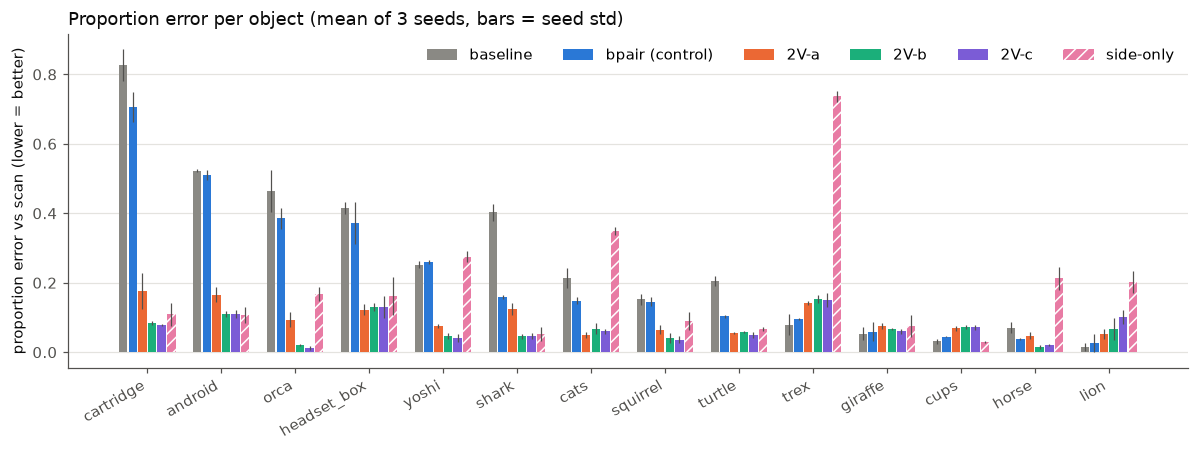

In [13]:
# Fig 2V-1: proportion error per object, grouped bars, 6 conditions, seed std as error bars
FIG_TAGS = ["baseline", "bpair", "2va", "2vb", "2vc", "side"]
order = list(prop_obj.loc[NAMES, "bpair"].sort_values(ascending=False).index)
sd_obj = runs.groupby(["tag", "name"]).prop_err.std().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.13
x = np.arange(len(order))
for i, t in enumerate(FIG_TAGS):
    ax.bar(x + (i - (len(FIG_TAGS) - 1) / 2) * w, prop_obj.loc[order, t], w * 0.88, yerr=sd_obj.loc[order, t],
           color=COLOR[t], hatch="///" if t == "side" else None, edgecolor="white", linewidth=0,
           error_kw={"elinewidth": 0.8, "ecolor": MUTED, "capsize": 0}, label=LABEL[t])
ax.set_xticks(x, order, rotation=30, ha="right")
ax.set_ylabel("proportion error vs scan (lower = better)")
ax.set_title("Proportion error per object (mean of 3 seeds, bars = seed std)", loc="left", color=INK)
ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2v_1_prop_err_per_object.png")
plt.show()

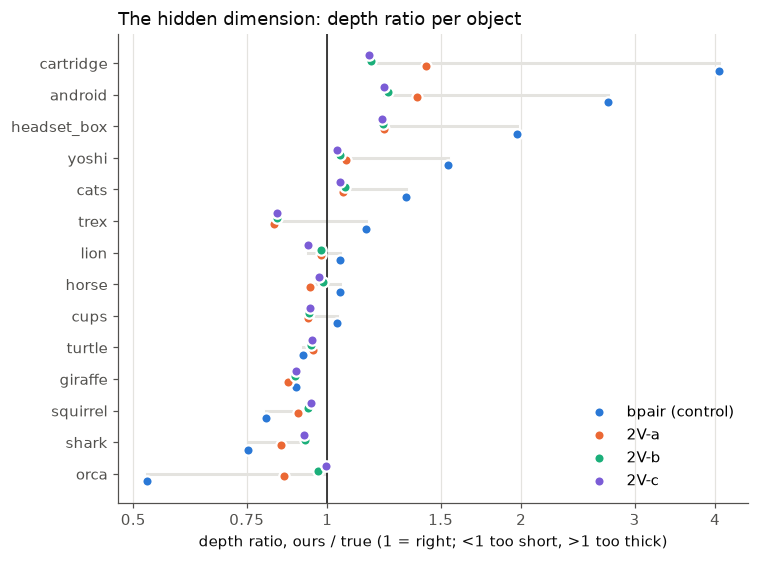

In [14]:
# Fig 2V-2: depth ratio dot plot (log scale, 1.0 = right), bpair vs 2V-a vs 2V-b vs 2V-c
DOT_TAGS = ["bpair", "2va", "2vb", "2vc"]
order_d = list(depth_obj["bpair"].sort_values().index)
y = np.arange(len(order_d))
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.axvline(1.0, color=INK, linewidth=1)
for n_i, n in enumerate(order_d):
    vals = depth_obj.loc[n, DOT_TAGS]
    ax.plot([vals.min(), vals.max()], [n_i, n_i], color=GRID, linewidth=2, zorder=1)
for i, t in enumerate(DOT_TAGS):
    ax.scatter(depth_obj.loc[order_d, t], y + (i - 1.5) * 0.16, s=46, color=COLOR[t],
               edgecolor="white", linewidth=1.5, zorder=3, label=LABEL[t])
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4], ["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.minorticks_off()
ax.set_yticks(y, order_d)
ax.grid(axis="y", visible=False)
ax.set_xlabel("depth ratio, ours / true (1 = right; <1 too short, >1 too thick)")
ax.set_title("The hidden dimension: depth ratio per object", loc="left", color=INK)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2v_2_depth_ratio.png")
plt.show()

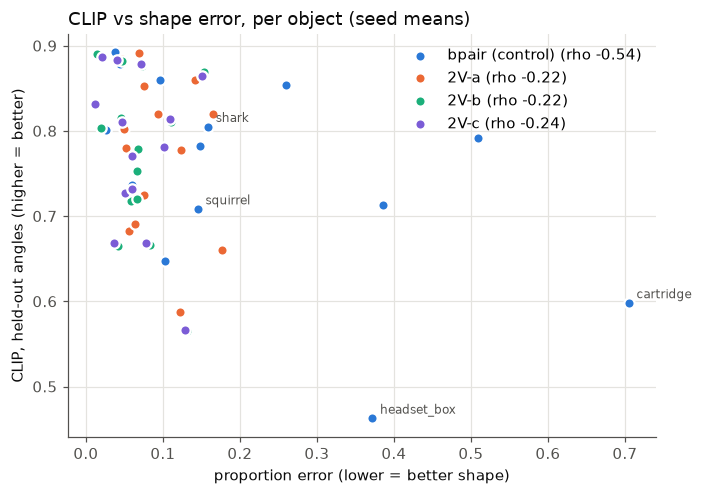

In [15]:
# Fig 2V-3: CLIP (held-out) vs proportion error, per object, same-reference conditions
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for t in DOT_TAGS:
    ax.scatter(prop_obj.loc[NAMES, t], held.loc[NAMES, t], s=46, color=COLOR[t],
               edgecolor="white", linewidth=1.5, label=f"{LABEL[t]} (rho {cv.loc['rho', t]:.2f})")
for n in ["cartridge", "shark", "squirrel", "headset_box"]:
    ax.annotate(n, (prop_obj.loc[n, "bpair"], held.loc[n, "bpair"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("proportion error (lower = better shape)")
ax.set_ylabel("CLIP, held-out angles (higher = better)")
ax.set_title("CLIP vs shape error, per object (seed means)", loc="left", color=INK)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2v_3_clip_vs_prop_err.png")
plt.show()

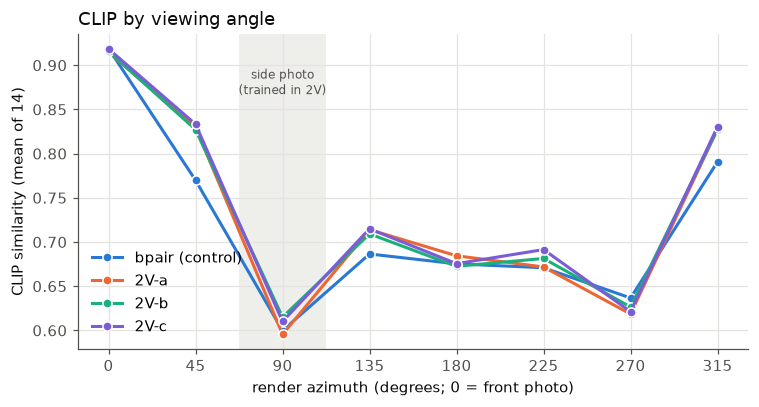

Figures and tables written to figures


In [16]:
# Fig 2V-4: per-angle CLIP, mean over 14 objects; 90 is a training photo for 2V (shaded)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvspan(67.5, 112.5, color=GRID, alpha=0.6, linewidth=0)
ax.text(90, 0.88, "side photo\n(trained in 2V)", ha="center", va="center", fontsize=8, color=MUTED)
for t in DOT_TAGS:
    ax.plot(ANGLES, per_angle.loc[t, ANGLES], color=COLOR[t], linewidth=2, marker="o", markersize=6,
            markeredgecolor="white", label=LABEL[t])
ax.set_xticks(ANGLES, [f"{a}" for a in ANGLES])
ax.set_xlabel("render azimuth (degrees; 0 = front photo)")
ax.set_ylabel("CLIP similarity (mean of 14)")
ax.set_title("CLIP by viewing angle", loc="left", color=INK)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2v_4_clip_per_angle.png")
plt.show()
print("Figures and tables written to", FIG_DIR.relative_to(ROOT))

## 9. Notes for Steven (from the outputs above, 2026-11-22)

Flags, not conclusions. Interpretation is the results section.

1. **`2v-results.md` checks out.** All 90 proportion-error values, all 84 depth ratios, the Wilcoxon table (mean change, objects better, p), seed spreads, the hindsight best single view (0.101, 9/14), the CLIP "All" rows, and the mesh / cap / time table recompute from the CSVs. **One mismatch:** side-only -> 2V-b, "all 3 seeds better" is **7** here, not 8 (section 4 prints the list).
2. **Method (section 2):** `prop_err` recomputes from the stored proportions (max difference 0.0002); side-only rows correctly swap the scan's width and depth; the scan proportions match the objects (cartridge 0.16 thin, orca 2.85 long). Caveats for the report: (a) axis-aligned boxes assume the object sits square to the scan's axes; a yawed object (two figurines in `cats`?) mixes width and depth. (b) The side photo's outline is a depth render of the same scan we score against, so part of bpair -> 2V is "the information got used"; 2V-a vs 2V-b is the clean comparison (already in the caveats).
3. **Control regressions are real, and they come from the photo, not the rule.** Lion and trex width ratios drop on all 3 seeds, and the drop is already there in 2V-a (lion 0.99 -> 0.92 -> 0.91, trex 0.95 -> 0.91 -> 0.88, seed means). Cups width drops a little in both 2V runs (0.95 -> 0.93 -> 0.92); horse only in 2V-b (1.03 -> 1.03 -> 1.00). So it arrives with the side photo, not with nearest-view conditioning. Lion's change does not beat 2x seed std; trex and cups do.
4. **Per-angle CLIP: the side photo does not fix the back.** Biggest gains bpair -> 2V-b are at 45 (+0.057) and 315 (+0.037); 135 +0.023; 180 and 270 flat or slightly down. 315 is on the side with no photo, so that gain looks like better shape, not copied texture. 90 barely moves because CLIP compares every render with the front photo.
5. **"CLIP is blind to STRETCH" is too strong.** Across objects, the CLIP change tracks the shape change (rho -0.65, bpair -> 2V-b). It misses individual cases (shark: proportion error 0.159 -> 0.046, CLIP +0.011). Suggest "CLIP partly tracks large shape fixes but misses specific ones."
6. **Failure-analysis tie-in:** STRETCH objects 0.372 -> 0.075 (bpair -> 2V-b), other -0.098, control +0.025. The gain is where the failure analysis said the problem was.
7. **2V-c (added 2026-11-27).** See the "2V-c" section after section 4: the report's Table V column and p-values recompute from the CSVs. Nearest (2V-b) and random (2V-c) are close on every object; the table there shows which differences, if any, beat 2x seed std. Wording in the report: "nearly the same shape" (2V-c is lower on most objects, but by tiny amounts; p 2vb -> 2vc printed in the stats table).
